# Algoritmos de classificação

Quatro algoritmos no mesmo problema: quem vai cancelar o contrato (churn). Qual se sai melhor?

Dados: Telco Customer Churn, Kaggle ([https://www.kaggle.com/datasets/blastchar/telco-customer-churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn), dados de exemplo da IBM). Salve o CSV como `dados/WA_Fn-UseC_-Telco-Customer-Churn.csv`.

In [1]:
import pandas as pd

dataset = pd.read_csv("dados/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# TotalCharges vem como texto, com 11 células vazias: vira número e essas linhas saem.
dataset["TotalCharges"] = pd.to_numeric(dataset["TotalCharges"], errors="coerce")
dataset = dataset.dropna(subset=["TotalCharges"])

# O alvo: Churn "Yes" = saiu = 1. "No" = ficou = 0.
y = (dataset["Churn"] == "Yes").astype(int)
print("clientes:", len(dataset))
print("% que sai:", round(y.mean(), 3))

clientes: 7032
% que sai: 0.266


In [2]:
# 4 colunas de entrada. 75% treino, 25% teste, com a mesma % de quem sai nos dois lados.
from sklearn.model_selection import train_test_split

numericas = ["tenure", "MonthlyCharges", "TotalCharges"]
X = dataset[numericas + ["Contract"]]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print("treino:", len(X_treino), "| teste:", len(X_teste))

treino: 5274 | teste: 1758


In [3]:
# O mesmo preparo para os 4 algoritmos:
# as numéricas na mesma escala (KNN e logística medem distância e somam pesos, então a escala muda o resultado)
# e Contract (texto) vira 3 colunas de 0 e 1.
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def preparo():
    return make_column_transformer(
        (StandardScaler(), numericas),
        (OneHotEncoder(), ["Contract"]),
        verbose_feature_names_out=False,
    )

In [4]:
# Treina, mede no teste e grava a run no MLflow. Os 4 algoritmos usam esta mesma função.
import os
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
import mlflow
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

mlflow.set_tracking_uri("mlruns")
mlflow.set_experiment("classificadores")

def avaliar(nome, modelo):
    modelo.fit(X_treino, y_treino)
    previsto = modelo.predict(X_teste)
    metricas = {
        "acuracia": accuracy_score(y_teste, previsto),
        "precisao": precision_score(y_teste, previsto, zero_division=0),
        "recall": recall_score(y_teste, previsto),
        "f1": f1_score(y_teste, previsto),
    }
    with mlflow.start_run(run_name=nome):
        mlflow.log_param("algoritmo", nome)
        mlflow.log_metrics(metricas)
    return {k: round(v, 3) for k, v in metricas.items()}

resultados = {}

/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/15 00:16:15 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026/10/15 00:16:15 INFO mlflow.tracking.fluent: Experiment with name 'classificadores' does not exist. Creating a new experiment.


**Baseline**: sem modelo nenhum, chuta sempre a resposta mais comum ("fica").

In [5]:
from sklearn.dummy import DummyClassifier

resultados["sempre fica"] = avaliar("sempre-fica", DummyClassifier(strategy="most_frequent"))
resultados["sempre fica"]

{'acuracia': 0.734, 'precisao': 0.0, 'recall': 0.0, 'f1': 0.0}

**Regressão logística**: soma peso × coluna (o score) e transforma essa soma numa probabilidade de 0 a 1.

In [6]:
from sklearn.linear_model import LogisticRegression

logistica = make_pipeline(preparo(), LogisticRegression(max_iter=1000))
resultados["logística"] = avaliar("logistica", logistica)
resultados["logística"]

{'acuracia': 0.788, 'precisao': 0.638, 'recall': 0.469, 'f1': 0.541}

**KNN**: procura os 5 clientes do treino mais parecidos e segue a maioria deles.

In [7]:
from sklearn.neighbors import KNeighborsClassifier

knn = make_pipeline(preparo(), KNeighborsClassifier(n_neighbors=5))
resultados["KNN"] = avaliar("knn", knn)
resultados["KNN"]

{'acuracia': 0.79, 'precisao': 0.629, 'recall': 0.507, 'f1': 0.562}

**Naive Bayes**: compara o cliente com o perfil médio de quem sai e de quem fica, uma coluna por vez, e junta as pistas.

In [8]:
from sklearn.naive_bayes import GaussianNB

bayes = make_pipeline(preparo(), GaussianNB())
resultados["Naive Bayes"] = avaliar("naive-bayes", bayes)
resultados["Naive Bayes"]

{'acuracia': 0.664, 'precisao': 0.432, 'recall': 0.833, 'f1': 0.569}

**Árvore de decisão**: faz perguntas de sim ou não ("contrato mensal?", "menos de X meses?") até chegar numa resposta. Aqui, no máximo 4 perguntas.

In [9]:
from sklearn.tree import DecisionTreeClassifier

arvore = make_pipeline(preparo(), DecisionTreeClassifier(max_depth=4, random_state=0))
resultados["árvore"] = avaliar("arvore", arvore)
resultados["árvore"]

{'acuracia': 0.786, 'precisao': 0.625, 'recall': 0.486, 'f1': 0.547}

A comparação, no teste.

In [10]:
tabela = pd.DataFrame(resultados).T
tabela

,acuracia,precisao,recall,f1
sempre fica,0.734,0.000,0.000,0.000
logística,0.788,0.638,0.469,0.541
KNN,0.790,0.629,0.507,0.562
Naive Bayes,0.664,0.432,0.833,0.569
árvore,0.786,0.625,0.486,0.547


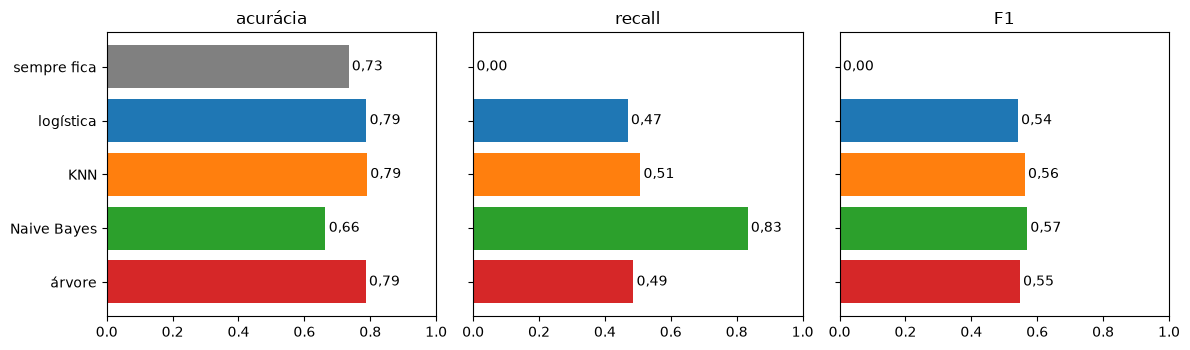

In [11]:
# Três métricas, uma barra por algoritmo. O valor fica escrito na ponta da barra.
import matplotlib.pyplot as plt

fig, paineis = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (coluna, titulo) in zip(paineis, [("acuracia", "acurácia"), ("recall", "recall"), ("f1", "F1")]):
    ax.barh(tabela.index, tabela[coluna], color=["gray", "tab:blue", "tab:orange", "tab:green", "tab:red"])
    for i, v in enumerate(tabela[coluna]):
        ax.text(v + 0.01, i, f"{v:.2f}".replace(".", ","), va="center")
    ax.set_title(titulo)
    ax.set_xlim(0, 1)
paineis[0].invert_yaxis()
plt.tight_layout()
plt.savefig("img/g-comparacao.png", dpi=150, bbox_inches="tight")
plt.show()

O mesmo cliente (posição 157 do teste) nos 4 modelos.

In [12]:
cliente = X_teste.iloc[[157]]
print(cliente)
print("real:", y_teste.iloc[157])

for nome, modelo in [("logística", logistica), ("KNN", knn), ("Naive Bayes", bayes), ("árvore", arvore)]:
    chance = modelo.predict_proba(cliente)[0, 1]
    print(f"{nome}: probabilidade de sair {chance:.2f} -> classe {modelo.predict(cliente)[0]}")

      tenure  MonthlyCharges  TotalCharges        Contract
6462       2           95.65         167.3  Month-to-month
real: 1
logística: probabilidade de sair 0.72 -> classe 1
KNN: probabilidade de sair 0.80 -> classe 1
Naive Bayes: probabilidade de sair 0.98 -> classe 1
árvore: probabilidade de sair 0.61 -> classe 1


In [13]:
# Logística: o score do cliente, antes de virar probabilidade.
print("score:", round(logistica.decision_function(cliente)[0], 2))

score: 0.95


In [14]:
# Logística: os pesos w. Peso + empurra para "sai". Peso − empurra para "fica".
pd.Series(logistica[-1].coef_[0], index=logistica[0].get_feature_names_out()).round(2)

tenure                    -1.23
MonthlyCharges             0.73
TotalCharges               0.39
Contract_Month-to-month    0.55
Contract_One year         -0.60
Contract_Two year         -1.30
dtype: float64

In [15]:
# KNN: os 5 vizinhos do cliente 157 no treino, e se cada um saiu.
# distancia = distância euclidiana, medida com as colunas já na mesma escala.
distancias, posicoes = knn[-1].kneighbors(knn[0].transform(cliente))
vizinhos = X_treino.iloc[posicoes[0]]
vizinhos.assign(saiu=y_treino.iloc[posicoes[0]].values, distancia=distancias[0].round(3))

,tenure,MonthlyCharges,TotalCharges,Contract,saiu,distancia
31,2,95.50,181.65,Month-to-month,0,0.008
969,2,96.00,174.80,Month-to-month,1,0.012
1148,2,95.15,196.90,Month-to-month,1,0.021
6066,2,94.95,178.10,Month-to-month,1,0.024
507,2,94.20,167.50,Month-to-month,1,0.048


In [16]:
# Naive Bayes: o perfil médio de quem fica (0) e de quem sai (1), no treino.
print("P(sai) antes de olhar o cliente:", round(bayes[-1].class_prior_[1], 3))
X_treino.groupby(y_treino)[numericas].mean().round(2)

P(sai) antes de olhar o cliente: 0.266


,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,37.55,61.60,2556.85
1,17.80,74.12,1508.23


In [17]:
# Árvore: as perguntas que o cliente 157 respondeu, com os cortes de volta em meses e US$.
escala = arvore[0].named_transformers_["standardscaler"]
nomes = arvore[0].get_feature_names_out()
regras = arvore[-1].tree_
Z = arvore[0].transform(cliente)
caminho = arvore[-1].decision_path(Z).indices

for no in caminho[:-1]:
    f = regras.feature[no]
    coluna, corte = nomes[f], regras.threshold[no]
    if coluna in numericas:
        i = numericas.index(coluna)
        lado = "<=" if Z[0, f] <= corte else ">"
        print(f"{coluna} {lado} {corte * escala.scale_[i] + escala.mean_[i]:.2f}")
    else:
        print(f"{coluna}?", "sim" if Z[0, f] > corte else "não")
print("clientes de treino nesta folha:", regras.n_node_samples[caminho[-1]])

Contract_Month-to-month? sim
MonthlyCharges > 68.72
tenure <= 15.50
TotalCharges > 118.10
clientes de treino nesta folha: 630


In [18]:
# Gini: 0 = grupo puro (todos saem ou todos ficam). Quanto mais misturado, maior.
# A árvore escolhe a pergunta que mais baixa o Gini.
sim, nao = regras.children_right[0], regras.children_left[0]
n = regras.n_node_samples
print("começo (todo o treino):", n[0], "clientes, Gini", round(regras.impurity[0], 3))
print("contrato mensal = sim:", n[sim], "clientes, Gini", round(regras.impurity[sim], 3))
print("contrato mensal = não:", n[nao], "clientes, Gini", round(regras.impurity[nao], 3))
media = (n[sim] * regras.impurity[sim] + n[nao] * regras.impurity[nao]) / n[0]
print("Gini médio depois da pergunta:", round(media, 3))
print("folha do cliente 157: Gini", round(regras.impurity[caminho[-1]], 3))

começo (todo o treino): 5274 clientes, Gini 0.39
contrato mensal = sim: 2920 clientes, Gini 0.49
contrato mensal = não: 2354 clientes, Gini 0.121
Gini médio depois da pergunta: 0.325
folha do cliente 157: Gini 0.475


Lendo a tabela:

- O chute "sempre fica" acerta 73,4% e não pega ninguém que sai (recall 0).
- Logística, KNN e árvore ficam perto de 0,79 de acurácia e pegam cerca de metade de quem sai (recall de 0,47 a 0,51).
- O Naive Bayes tem a menor acurácia (0,664), mas pega 83% de quem sai (recall 0,833) e tem o maior F1 (0,569). Em troca, dá mais alarmes à toa (precisão 0,432).
- Qual escolher depende do erro que custa mais: perder cliente → Naive Bayes. Ligar à toa → logística (maior precisão, 0,638) ou KNN.

`MLFLOW_ALLOW_FILE_STORE=true mlflow ui --backend-store-uri mlruns`